<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/03_DDoS_DoS_Detection/HybridQNN_DDoSDetection_Sarvade2025.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hybrid classical-quantum neural network (C-QNN) for DDoS detection in software-defined vehicular networks: Sarvade et al. (2025) step by step

This notebook re-implements, runs and checks the experiment of

> Varun P. Sarvade, Shrirang Ambaji Kulkarni and C. Vidya Raj,
> "A Hybrid Classical-Quantum Neural Network Model for DDoS Attack Detection in Software-Defined Vehicular Networks",
> *Information* 16(9), 722, 2025. DOI [10.3390/info16090722](https://doi.org/10.3390/info16090722)

The paper compares three quantum-machine-learning detectors on two public DDoS data sets: a hybrid **C-QNN** (PennyLane quantum circuit
between PCA and a small classical network), a **C-QBM** (quantum Boltzmann machine) and a **C-QKM** (quantum k-means). It reports about 99.9 % accuracy
on CIC-DDoS2019 and 90 % on the Kaggle "DDoS SDN" data set (Tables 5 and 6).

**What the notebook does.**
1. Downloads the two public data sets of the paper: the **DDoS SDN data set** (Ahuja et al., Mendeley Data, the file behind the Kaggle copy) and a labelled, class-balanced
   mirror of **CIC-DDoS2019** (Hugging Face `RonaldoMPF/CIC-DDoS2019-15C`).
2. Preprocesses them exactly as the paper says (standardise, PCA, fitted on the training split only), draws the real class distributions and 2-D projections of the real flows.
3. Builds the C-QNN of Algorithm 1 (angle embedding, `StronglyEntanglingLayers`, Pauli-Z read-out, `Dense`-ReLU-`Dense`-sigmoid head, binary cross-entropy, Adam, batch size 5, 30 epochs)
   with the hyper-parameters of Table 3, draws the circuits that are executed, and trains it.
4. Re-implements the paper's C-QKM (k-means with a quantum overlap distance) and C-QBM (a circuit Born machine used as an anomaly detector) as documented reconstructions.
5. Trains classical baselines on exactly the same inputs (random forest, RBF-SVM, a classical network with the same head) and prints the paper's Tables 5 and 6 next to the notebook's numbers with a verdict per claim.

**How to run.** Colab, CPU runtime, *Runtime -> Run all*. With `FAST_MODE = True` (small samples, few epochs, one seed) it takes a few minutes; with `FAST_MODE = False`
(30 epochs as in the paper, three seeds) it takes roughly 40-60 minutes on a CPU. No quantum hardware, no account and no Hugging Face token are needed (both data sets are open).
If you ever point the notebook at a gated Hugging Face data set, add your own token as a Colab Secret named `HF_TOKEN`; the notebook reads it from `os.environ["HF_TOKEN"]` or Colab Secrets and never prints it.

**What you get at the end.** A table "paper vs this notebook" with a verdict per claim, confusion matrices, loss curves, the quantum circuits and critical remarks.

## The paper in one page

**Problem.** The central controller of a software-defined vehicular network (SDVN = SDN + vehicular ad hoc network) is a single point of failure; a DDoS flood can overload it.
The authors want a lightweight detector that runs in the application plane of the Ryu controller and labels each flow *benign* or *DDoS*.

**Decision.** Binary classification of flow records (`0` benign, `1` DDoS). Metrics: accuracy, precision, recall, F1 (Eqs. 8-11); for the clustering model also the
adjusted Rand index (ARI), normalised mutual information (NMI) and the silhouette score (Eqs. 12-14).

**Method (Section 3, Algorithm 1, Table 3).**
* Standardise every feature (Eq. 1), then PCA (Eq. 2). The text keeps **four** components "because the quantum circuit supports four qubits"; Table 3 lists "PCA components = 2" for every row.
* **C-QNN**: `AngleEmbedding` (one `RY(x_i)` per qubit, Eq. 3) -> `StronglyEntanglingLayers` (Eq. 4) -> `<Z_i>` of every qubit -> `Dense(m)` + ReLU -> `Dense(1)` + sigmoid
  -> binary cross-entropy (Eq. 7). Adam, batch size 5, 30 epochs, 70 % / 30 % split. Table 3: CIC-DDoS2019 uses **2 qubits, 1 layer, learning rate 0.01**; Kaggle DDoS SDN uses **4 qubits, 3 layers, default Adam learning rate**.
* **C-QBM**: "leverages quantum probability distributions for identifying anomalies" (2 qubits, Adam, learning rate 0.005 / 0.05, 30 epochs). **C-QKM**: iterative quantum k-means (4 qubits on CIC-DDoS2019, 2 on Kaggle, 30 iterations).
* Software: PennyLane 0.23, TensorFlow/Keras, Mininet-WiFi and the Ryu controller for a flooding test bed (Algorithm 2, hping3 UDP flood). **No result of the test bed is reported**, only Tables 5 and 6.

**Data.** The Kaggle *DDoS SDN* data set (23 columns, Mininet + Ryu, benign TCP/UDP/ICMP and TCP-SYN / UDP / ICMP floods) and CIC-DDoS2019 (80+ features, 11 attack types). Neither is vehicular.

**Claims to check.**

| Data set | Model | Accuracy | Precision | Recall | F1 | ARI | NMI | Silhouette |
|---|---|---|---|---|---|---|---|---|
| CIC-DDoS2019 (Table 5) | C-QNN | 0.9989 | 0.99 | 0.9994 | 0.99 | - | - | - |
| CIC-DDoS2019 | C-QBM | 0.5062 | 0.9933 | 0.5068 | 0.6712 | - | - | - |
| CIC-DDoS2019 | C-QKM | 0.9988 | 0.99 | 0.9988 | 0.99 | 0.9075 | 0.8431 | 0.9772 |
| Kaggle DDoS SDN (Table 6) | C-QNN | 0.8996 | 0.7855 | 0.8364 | 0.8109 | - | - | - |
| Kaggle DDoS SDN | C-QBM | 0.6108 | 0.7692 | 0.0039 | 0.0065 | - | - | - |
| Kaggle DDoS SDN | C-QKM | 0.6219 | 0.5107 | 0.7247 | 0.5992 | 0.0588 | 0.05746 | 0.1791 |

The qualitative claim is that C-QNN is the best of the three on both data sets.

## What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Kaggle DDoS SDN data | `aikenkazin/ddos-sdn-dataset` on Kaggle (login needed) | the original source of that file: Ahuja, Singal, Mukhopadhyay, *DDOS attack SDN Dataset*, Mendeley Data, DOI 10.17632/jxpfjc64kr.1 (CC BY 4.0), `dataset_sdn.csv`, 104,345 rows (103,839 complete rows used), 23 columns; sha-256 checked |
| CIC-DDoS2019 | UNB-CIC original files (80+ flow features, tens of GB) | `RonaldoMPF/CIC-DDoS2019-15C` on Hugging Face: a published preprocessed copy of CIC-DDoS2019 with **14 selected flow features**, 11 attack types plus BENIGN, 50,000 flows per class. **Deviation: 14 instead of 80+ features** |
| CIC label | benign vs DDoS | `BENIGN` = 0, any of the 11 attack types = 1 (attack is the positive class); the attack family is kept for plots |
| Class balance (CIC) | not stated | balanced sample: half benign, half attack (attacks drawn uniformly from the 11 families); the mirror itself is balanced per class, so natural proportions do not exist in it |
| Sample size | whole data sets (not stated) | `N_CIC`, `N_KAG` flows (random sample, seeded) because a CPU circuit simulator trains with batch size 5; budgets in the configuration cell |
| Split | 70 % / 30 % | stratified 70 / 30 |
| Kaggle features | 22 inputs: dt, switch, IPs, packet/byte counts, durations, ports, rates ... | all 22 inputs. `src` / `dst` -> last IPv4 octet (the addresses are 10.0.0.x); `Protocol` -> one-hot TCP/UDP/ICMP; ablation without `dt`, `src`, `dst` |
| Preprocessing | `StandardScaler` -> PCA (Eqs. 1-2) | the same, fitted on the training split only. **Ablation:** signed `log1p` before standardising (the CIC features have extreme tails) |
| PCA components | text: 4; Table 3: 2 | CIC-DDoS2019: 2 (= 2 qubits, consistent). Kaggle: **4** (= 4 qubits, Eq. 2/3). Variant "Table 3 literal": 2 components embedded on the first 2 of the 4 qubits |
| Angle range | the PCA coordinates are used directly as `RY` angles | primary variant: raw PCA coordinates. Variant: coordinates min-max scaled to [0, pi] (fitted on the training split, test clipped) |
| Circuit | `AngleEmbedding(RY)` + `StronglyEntanglingLayers` + `<Z_i>` | exactly that template of PennyLane 0.45 (default CNOT ring with ranges `l mod (n-1) + 1`); weights initialised uniformly in [0, 2 pi] (the PennyLane/Keras layer default) |
| Classical head | `Dense(m)`-ReLU-`Dense(1)`-sigmoid, `m` not given | **`m = 16`** |
| Optimiser | Adam; lr 0.01 (CIC), "default" (Kaggle) | Adam, lr 0.01 (CIC), 0.001 (Kaggle, the Keras default), batch size 5, 30 epochs (`EPOCHS`) in the full run |
| Framework | PennyLane 0.23 + TensorFlow 2.3 / Keras 2.10 | PennyLane 0.45 + PyTorch. The circuit is trained with an exact state-vector simulator written in PyTorch and **asserted equal (1e-9) to the PennyLane QNode** (see section 4); the PennyLane QNode is used for the drawings and for the final check |
| C-QKM | "iterative update", quantum distance not specified | k = 2 clusters; distance `1 - |<phi(x)|phi(c)>|^2` evaluated by a PennyLane compute-uncompute circuit; farthest-point initialisation; centroids updated classically; cluster -> label by majority of the training points. Qubits as in Table 3 (4 on CIC, 2 on Kaggle) |
| C-QBM | "quantum probability distributions", details not given | circuit Born machine (2 qubits, `StronglyEntanglingLayers`), trained on the **benign** training flows only (each flow reduced to 2 bits: PCA component above/below its training median), cross-entropy loss, Adam with lr 0.005 (CIC) / 0.05 (Kaggle), 30 epochs; attack if the benign model gives the flow's bit pattern a probability below a threshold chosen on the training split |
| Baselines | none | `RandomForest(100)` and `SVC(rbf)` on the same PCA inputs, the same network with a classical layer instead of the circuit, and a random forest on all features |
| Seeds | not stated | `SEEDS` list, mean +- std |
| SDVN test bed | Mininet-WiFi + Ryu + hping3 (Algorithm 2) | **not reproduced**: needs a Linux emulator stack, and the paper gives no test-bed result |

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib, torch and seaborn.
# The pip line runs on Colab (or wherever PennyLane is missing); a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("pennylane") is None:
    %pip install -q "pennylane==0.45.1" "huggingface_hub>=0.30" requests
    print("PennyLane installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("pennylane already present; skipping pip install.")

pennylane already present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE = False            # True: small class demo in a few minutes. False: full run (about 40-60 minutes on a CPU, 30 epochs as in the paper).
SEED      = 42              # master seed (CHOICE: the paper gives none)

if FAST_MODE:
    N_CIC, N_KAG = 1500, 1500    # flows sampled from each data set (CHOICE)
    EPOCHS       = 3             # paper: 30
    SEEDS        = [42]
    EPOCHS_QBM   = 10            # paper: 30
else:
    N_CIC, N_KAG = 3000, 3000
    EPOCHS       = 30           # paper: "a maximum of 30 epochs"
    SEEDS        = [42, 43, 44]
    EPOCHS_QBM   = 30

TEST_SIZE   = 0.30          # paper: 70 % train / 30 % test
BATCH       = 5             # Table 3
HIDDEN      = 16            # CHOICE: width m of the hidden Dense layer (not given in the paper)
KMEANS_ITERS = 30           # Table 3 lists 30 "epochs" for C-QKM
BORN_BATCH  = 128           # CHOICE: mini-batch of benign flows for the C-QBM
N_PCA_MAX   = 4             # PCA is fitted with 4 components once; every model slices the first n

# Table 3 hyper-parameters
HP = {
    "CIC-DDoS2019":    dict(qnn_qubits=2, qnn_layers=1, qnn_lr=0.01,  qkm_qubits=4, qbm_qubits=2, qbm_lr=0.005),
    "Kaggle DDoS SDN": dict(qnn_qubits=4, qnn_layers=3, qnn_lr=0.001, qkm_qubits=2, qbm_qubits=2, qbm_lr=0.05),
}

DATA_DIR    = "sarvade2025_data"                     # cache folder
KAGGLE_URL  = "https://data.mendeley.com/public-files/datasets/jxpfjc64kr/files/5b57518c-c0fa-4cd9-bc11-e01bd5a363f4/file_downloaded"
KAGGLE_SHA256 = "e0d9fa511e57b849bf15fbd1d0ac91a83bbd4ad55706eadffe077de6246e4dd3"
KAGGLE_PATH = None                                   # or the path of an uploaded dataset_sdn.csv (e.g. from the Kaggle download)
CIC_REPO    = "RonaldoMPF/CIC-DDoS2019-15C"          # Hugging Face mirror (train.csv + test.csv)
IBM_TOKEN   = ""                                     # unused: the experiment needs no quantum hardware
print(f"FAST_MODE={FAST_MODE}  N_CIC={N_CIC}  N_KAG={N_KAG}  EPOCHS={EPOCHS}  SEEDS={SEEDS}")

FAST_MODE=False  N_CIC=3000  N_KAG=3000  EPOCHS=30  SEEDS=[42, 43, 44]


In [3]:
import os, time, math, hashlib, warnings, json
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
import pennylane as qml
import sklearn, requests
from huggingface_hub import hf_hub_download
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, adjusted_rand_score,
                             normalized_mutual_info_score, silhouette_score, confusion_matrix, ConfusionMatrixDisplay)
warnings.filterwarnings("ignore")

def set_all_seeds(seed):
    np.random.seed(seed); torch.manual_seed(seed)

set_all_seeds(SEED)
rng = np.random.default_rng(SEED)
torch.set_num_threads(1)               # tiny tensors: one thread is fastest and avoids oversubscription on shared machines
os.makedirs(DATA_DIR, exist_ok=True)
print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| torch", torch.__version__,
      "| pennylane", qml.__version__, "| matplotlib", matplotlib.__version__)

numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1 | torch 2.14.1+cpu | pennylane 0.45.1 | matplotlib 3.11.2


## 1. Data: the two data sets of the paper

* **Kaggle "DDoS SDN"** (Ahuja, Singal, Mukhopadhyay 2020). Ten random Mininet topologies with one Ryu controller; benign TCP / UDP / ICMP traffic and malicious TCP-SYN, UDP and ICMP floods;
  flow statistics are read from the switches every 30 s. 23 columns, label `0` = benign, `1` = malicious. The notebook downloads the original file from Mendeley Data (the Kaggle file is a copy) and checks its sha-256 hash.
* **CIC-DDoS2019** (Sharafaldin et al., Canadian Institute for Cybersecurity). The original CSV files are several GB each. The notebook uses a published, preprocessed copy
  with 14 selected flow features and 50,000 flows for each of the 12 classes (BENIGN + 11 DDoS types).

Both are open: no token is required. The token cell is nevertheless present because the project convention is to resolve a Hugging Face token only from `os.environ["HF_TOKEN"]` or Colab Secrets; a token
is never printed or stored.

In [4]:
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN (optional here: the data are open)
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

# ---- Kaggle DDoS SDN (Mendeley Data, original source) ----
if KAGGLE_PATH is None:
    KAGGLE_PATH = os.path.join(DATA_DIR, "dataset_sdn.csv")
    if not os.path.exists(KAGGLE_PATH):
        r = requests.get(KAGGLE_URL, headers={"User-Agent": "Mozilla/5.0"}, timeout=180); r.raise_for_status()
        with open(KAGGLE_PATH, "wb") as fh: fh.write(r.content)
    digest = hashlib.sha256(open(KAGGLE_PATH, "rb").read()).hexdigest()
    print("dataset_sdn.csv sha-256 matches Mendeley record:", digest == KAGGLE_SHA256)
KAG_RAW = pd.read_csv(KAGGLE_PATH)
print("Kaggle DDoS SDN as downloaded:", KAG_RAW.shape, "| rows with a missing value (rx_kbps / tot_kbps):", int(KAG_RAW.isna().any(axis=1).sum()))
KAG_RAW = KAG_RAW.dropna().reset_index(drop=True)          # CHOICE: drop the 506 rows (0.5 %) with missing rates; the 5,091 exact duplicate rows are kept
print("Kaggle DDoS SDN after dropping them:", KAG_RAW.shape)

# ---- CIC-DDoS2019 (Hugging Face mirror with 14 features, 12 balanced classes) ----
frames = []
for fn in ["train.csv", "test.csv"]:
    p = hf_hub_download(CIC_REPO, fn, repo_type="dataset", local_dir=DATA_DIR, token=HF_TOKEN)
    frames.append(pd.read_csv(p))
CIC_RAW = pd.concat(frames, ignore_index=True)
CIC_RAW.columns = [c.strip() for c in CIC_RAW.columns]
print("CIC-DDoS2019 (14-feature mirror):", CIC_RAW.shape)

dataset_sdn.csv sha-256 matches Mendeley record: True


Kaggle DDoS SDN as downloaded: (104345, 23) | rows with a missing value (rx_kbps / tot_kbps): 506
Kaggle DDoS SDN after dropping them: (103839, 23)


CIC-DDoS2019 (14-feature mirror): (600000, 15)


## 2. Cleaning, labels and preprocessing

**Kaggle.** `src` and `dst` are strings like `10.0.0.7`; they become the last octet (CHOICE). `Protocol` becomes three indicator columns. Everything else is numeric already; the 506 rows with a missing `rx_kbps` / `tot_kbps` are dropped (CHOICE) and the 5,091 exact duplicate rows are kept, since the paper does not mention removing them.
Feature sets: `all22` (every input of the data set; the paper does not say that anything was dropped) and `no_ids` (without the time stamp `dt` and the two addresses, to see whether the model relies on them).

**CIC-DDoS2019.** The 14 columns are numeric; infinities are replaced by NaN and the few NaN flows are dropped. The binary label is `BENIGN` -> 0, any attack -> 1.

**Preprocessing** (Eqs. 1-2, every transform fitted on the training split only): optional signed `log1p`, `StandardScaler`, `PCA(4)`, and for the "scaled" variants `MinMaxScaler((0, pi))` on the first components with the test angles clipped to [0, pi].
Constant columns of the training split are dropped first.

The **variants** below (three for CIC-DDoS2019, four for the Kaggle set) are the paper's pipeline (`paper`) and documented departures from it; only `paper` is used for the verdicts, the others are reported as ablations.

In [5]:
KAG_FEATS_ALL = [c for c in KAG_RAW.columns if c != "label"]
KAG_FEATS_NOID = [c for c in KAG_FEATS_ALL if c not in ("dt", "src", "dst")]

def kag_frame(df):
    d = df.copy()
    for c in ("src", "dst"):
        d[c] = d[c].astype(str).str.split(".").str[-1].astype(int)         # CHOICE: last octet of 10.0.0.x
    proto = pd.get_dummies(d["Protocol"]).reindex(columns=["TCP", "UDP", "ICMP"], fill_value=0).astype(int)
    return pd.concat([d.drop(columns=["Protocol", "label"]), proto], axis=1)

CIC_FEATS = [c for c in CIC_RAW.columns if c != "Label"]

# variant = dict(feats, log, scaled, pca). "paper" is the pipeline of the paper; the rest are ablations (first seed only).
def variants_for(ds):
    if ds == "CIC-DDoS2019":
        return {"paper": dict(log=False, scaled=False, pca=2),
                "log1p": dict(log=True, scaled=False, pca=2),
                "log1p+[0,pi]": dict(log=True, scaled=True, pca=2)}
    kf = kag_frame(KAG_RAW.head(5)).columns.tolist()
    return {"paper": dict(log=False, scaled=False, pca=4, cols=kf),
            "[0,pi]": dict(log=False, scaled=True, pca=4, cols=kf),
            "Table3 PCA2": dict(log=False, scaled=False, pca=2, cols=kf),
            "no_ids": dict(log=False, scaled=False, pca=4, cols=[c for c in kf if c not in ("dt", "src", "dst")])}

DATASETS = ["CIC-DDoS2019", "Kaggle DDoS SDN"]
VARIANTS = {ds: variants_for(ds) for ds in DATASETS}

_SAMPLES = {}
def get_sample(ds, seed):
    """Seeded sample + stratified 70/30 split (independent of the variant, so variants share the same flows)."""
    key = (ds, seed)
    if key in _SAMPLES: return _SAMPLES[key]
    if ds == "Kaggle DDoS SDN":
        d = KAG_RAW.sample(min(N_KAG, len(KAG_RAW)), random_state=seed)
        y = d["label"].to_numpy().astype(int)
        X = kag_frame(d); fam = d["Protocol"].to_numpy()
        raw_lab = d["label"].to_numpy()
    else:
        d = CIC_RAW.replace([np.inf, -np.inf], np.nan).dropna()
        ben = d[d["Label"] == "BENIGN"].sample(N_CIC // 2, random_state=seed)
        att = d[d["Label"] != "BENIGN"].sample(N_CIC // 2, random_state=seed)
        d = pd.concat([ben, att]).sample(frac=1.0, random_state=seed)
        y = (d["Label"] != "BENIGN").astype(int).to_numpy()
        X = d[CIC_FEATS]; fam = d["Label"].to_numpy(); raw_lab = fam
    X = X.reset_index(drop=True)
    itr, ite = train_test_split(np.arange(len(y)), test_size=TEST_SIZE, stratify=y, random_state=seed)
    s = dict(X=X, y=y, fam=fam, raw_lab=raw_lab, itr=itr, ite=ite)
    _SAMPLES[key] = s
    return s

def slog(a): return np.sign(a) * np.log1p(np.abs(a))

def prepare(ds, seed, vname="paper"):
    """Optional signed log -> StandardScaler -> PCA(4), fitted on the training split only; raw and [0, pi]-scaled angles."""
    v = VARIANTS[ds][vname]; s = get_sample(ds, seed)
    X = s["X"][v["cols"]] if "cols" in v else s["X"]
    Xtr_df, Xte_df = X.iloc[s["itr"]], X.iloc[s["ite"]]
    keep = Xtr_df.columns[Xtr_df.nunique() > 1]                  # drop constant training columns
    Xtr, Xte = Xtr_df[keep].to_numpy(float), Xte_df[keep].to_numpy(float)
    if v["log"]: Xtr, Xte = slog(Xtr), slog(Xte)
    sc = StandardScaler().fit(Xtr)
    pca = PCA(n_components=min(N_PCA_MAX, Xtr.shape[1]), random_state=seed).fit(sc.transform(Xtr))
    Ztr, Zte = pca.transform(sc.transform(Xtr)), pca.transform(sc.transform(Xte))
    k = v["pca"]
    if v["scaled"]:
        mm = MinMaxScaler((0, np.pi)).fit(Ztr[:, :k])
        Atr, Ate = mm.transform(Ztr[:, :k]), np.clip(mm.transform(Zte[:, :k]), 0, np.pi)
    else:
        Atr, Ate = Ztr[:, :k], Zte[:, :k]
    mm4 = MinMaxScaler((0, np.pi)).fit(Ztr)                      # [0, pi] version of all 4 coordinates (used for plots and one C-QKM row)
    Zte4s = np.clip(mm4.transform(Zte), 0, np.pi)
    return dict(Zte4s=Zte4s,ds=ds, seed=seed, variant=vname, feats=list(keep), Xtr=Xtr, Xte=Xte, ytr=s["y"][s["itr"]], yte=s["y"][s["ite"]],
                fam_tr=s["fam"][s["itr"]], fam_te=s["fam"][s["ite"]], Ztr=Ztr, Zte=Zte, Atr=Atr, Ate=Ate,
                Ztr4s=mm4.transform(Ztr), evr=pca.explained_variance_ratio_)

PREP = {ds: prepare(ds, SEED, "paper") for ds in DATASETS}
for ds, p in PREP.items():
    print(f"[{ds}] train {p['Xtr'].shape}, test {p['Xte'].shape}, PCA(4) variance kept {p['evr'].sum():.3f}, model input {p['Atr'].shape[1]} angles")

[CIC-DDoS2019] train (2100, 14), test (900, 14), PCA(4) variance kept 0.708, model input 2 angles
[Kaggle DDoS SDN] train (2100, 24), test (900, 24), PCA(4) variance kept 0.539, model input 4 angles


## Dataset Exploration and Visualisation

Everything in this section is drawn from the **real flows** loaded above: no synthetic or placeholder points. First the numbers (shapes, feature names, original label values and
counts), then the class distributions, then two-dimensional projections of the real training flows coloured by their ground-truth label: the raw PCA coordinates (PCA fitted on the training split)
and the same coordinates scaled to angles in [0, pi]. For CIC-DDoS2019 the colours are the 12 original classes (BENIGN and the 11 attack families); for the Kaggle SDN set they are
the original binary label split by the traffic protocol (the only finer-grained information the data set has).

### Shapes, features and original labels

In [6]:
print("=== Kaggle DDoS SDN (Mendeley dataset_sdn.csv) ===")
print("shape:", KAG_RAW.shape)
print("original columns:", list(KAG_RAW.columns))
print("original label values (0 = benign, 1 = malicious):"); print(KAG_RAW["label"].value_counts().to_string())
print("\nprotocol x label:"); print(pd.crosstab(KAG_RAW["Protocol"], KAG_RAW["label"]).to_string())
print("\nmodel input columns after encoding:", VARIANTS["Kaggle DDoS SDN"]["paper"]["cols"])
p = PREP["Kaggle DDoS SDN"]
print(f"sample at seed {SEED}: train {p['Xtr'].shape}, test {p['Xte'].shape}; train label counts {np.bincount(p['ytr'])}, test {np.bincount(p['yte'])}")

print("\n=== CIC-DDoS2019 (Hugging Face mirror CIC-DDoS2019-15C, train.csv + test.csv) ===")
print("shape:", CIC_RAW.shape)
print("original feature names:", CIC_FEATS)
print("original label values and counts:"); print(CIC_RAW["Label"].value_counts().to_string())
p = PREP["CIC-DDoS2019"]
print(f"\nbalanced sample at seed {SEED}: train {p['Xtr'].shape}, test {p['Xte'].shape}; train label counts (0 benign, 1 attack) {np.bincount(p['ytr'])}, test {np.bincount(p['yte'])}")
print("attack families in the sample (train):"); print(pd.Series(p["fam_tr"]).value_counts().to_string())

=== Kaggle DDoS SDN (Mendeley dataset_sdn.csv) ===
shape: (103839, 23)
original columns: ['dt', 'switch', 'src', 'dst', 'pktcount', 'bytecount', 'dur', 'dur_nsec', 'tot_dur', 'flows', 'packetins', 'pktperflow', 'byteperflow', 'pktrate', 'Pairflow', 'Protocol', 'port_no', 'tx_bytes', 'rx_bytes', 'tx_kbps', 'rx_kbps', 'tot_kbps', 'label']
original label values (0 = benign, 1 = malicious):
label
0    63335
1    40504

protocol x label:
label         0      1
Protocol              
ICMP      31902   9419
TCP       15570  13866
UDP       15863  17219

model input columns after encoding: ['dt', 'switch', 'src', 'dst', 'pktcount', 'bytecount', 'dur', 'dur_nsec', 'tot_dur', 'flows', 'packetins', 'pktperflow', 'byteperflow', 'pktrate', 'Pairflow', 'port_no', 'tx_bytes', 'rx_bytes', 'tx_kbps', 'rx_kbps', 'tot_kbps', 'TCP', 'UDP', 'ICMP']
sample at seed 42: train (2100, 24), test (900, 24); train label counts [1270  830], test [544 356]

=== CIC-DDoS2019 (Hugging Face mirror CIC-DDoS2019-15C, tra

Label
UDP-lag          50000
DrDoS_SNMP       50000
DrDoS_DNS        50000
BENIGN           50000
DrDoS_UDP        50000
DrDoS_LDAP       50000
DrDoS_SSDP       50000
DrDoS_MSSQL      50000
Syn              50000
DrDoS_NetBIOS    50000
TFTP             50000
DrDoS_NTP        50000

balanced sample at seed 42: train (2100, 14), test (900, 14); train label counts (0 benign, 1 attack) [1050 1050], test [450 450]
attack families in the sample (train):
BENIGN           1050
Syn               108
DrDoS_LDAP        107
DrDoS_SSDP        105
DrDoS_MSSQL       104
UDP-lag           103
DrDoS_UDP         101
DrDoS_DNS          97
DrDoS_NetBIOS      89
DrDoS_NTP          82
TFTP               82
DrDoS_SNMP         72


### Real class distributions

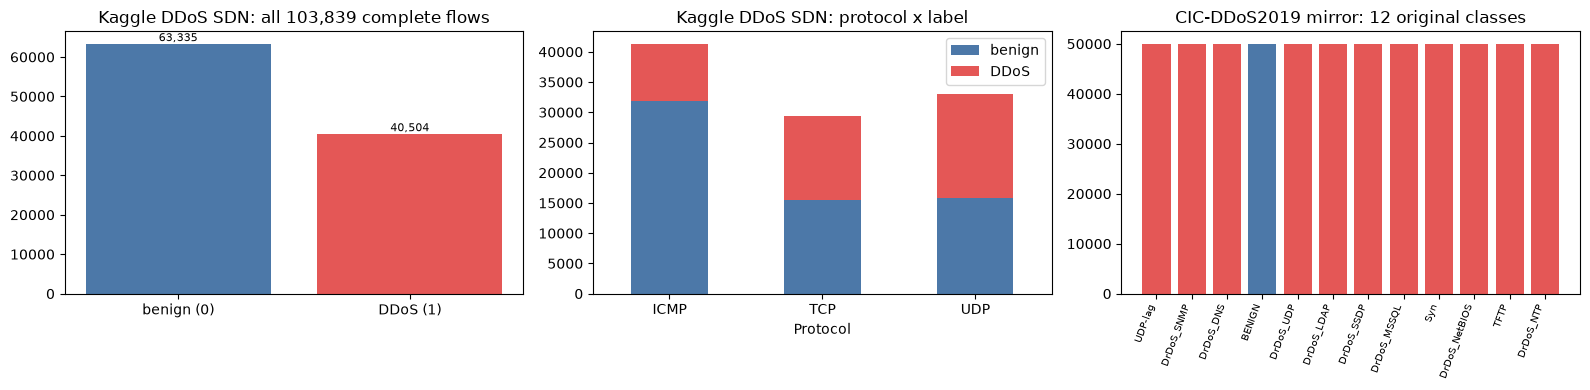

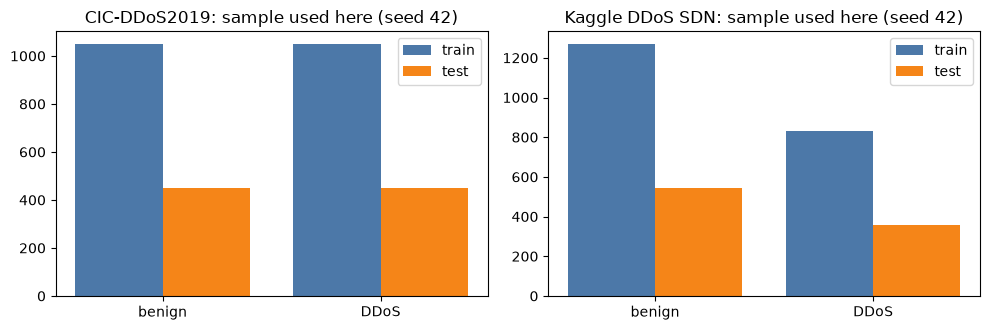

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
vc = KAG_RAW["label"].value_counts().sort_index()
axes[0].bar(["benign (0)", "DDoS (1)"], vc.values, color=["#4C78A8", "#E45756"])
for i, v in enumerate(vc.values): axes[0].text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=8)
axes[0].set_title("Kaggle DDoS SDN: all 103,839 complete flows")
ct = pd.crosstab(KAG_RAW["Protocol"], KAG_RAW["label"])
ct.plot(kind="bar", stacked=True, ax=axes[1], color=["#4C78A8", "#E45756"], rot=0); axes[1].set_title("Kaggle DDoS SDN: protocol x label")
axes[1].legend(["benign", "DDoS"])
cvc = CIC_RAW["Label"].value_counts()
axes[2].bar(range(len(cvc)), cvc.values, color=["#4C78A8" if k == "BENIGN" else "#E45756" for k in cvc.index])
axes[2].set_xticks(range(len(cvc))); axes[2].set_xticklabels(cvc.index, rotation=70, ha="right", fontsize=7)
axes[2].set_title("CIC-DDoS2019 mirror: 12 original classes")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, ds in zip(axes, DATASETS):
    p = PREP[ds]; xs = np.arange(2)
    ax.bar(xs - 0.2, np.bincount(p["ytr"]), 0.4, label="train", color="#4C78A8"); ax.bar(xs + 0.2, np.bincount(p["yte"]), 0.4, label="test", color="#F58518")
    ax.set_xticks(xs); ax.set_xticklabels(["benign", "DDoS"]); ax.legend(); ax.set_title(f"{ds}: sample used here (seed {SEED})")
plt.tight_layout(); plt.show()

### Real flows in two dimensions, coloured by the true label

Left: the first two principal components of the **training** flows (standardised, PCA fitted on the training split). Right: the same two coordinates min-max scaled to [0, pi]
(the angle range of an `RY` embedding; the primary C-QNN uses the left-hand raw coordinates as angles, as the paper does). Every point is one real flow.

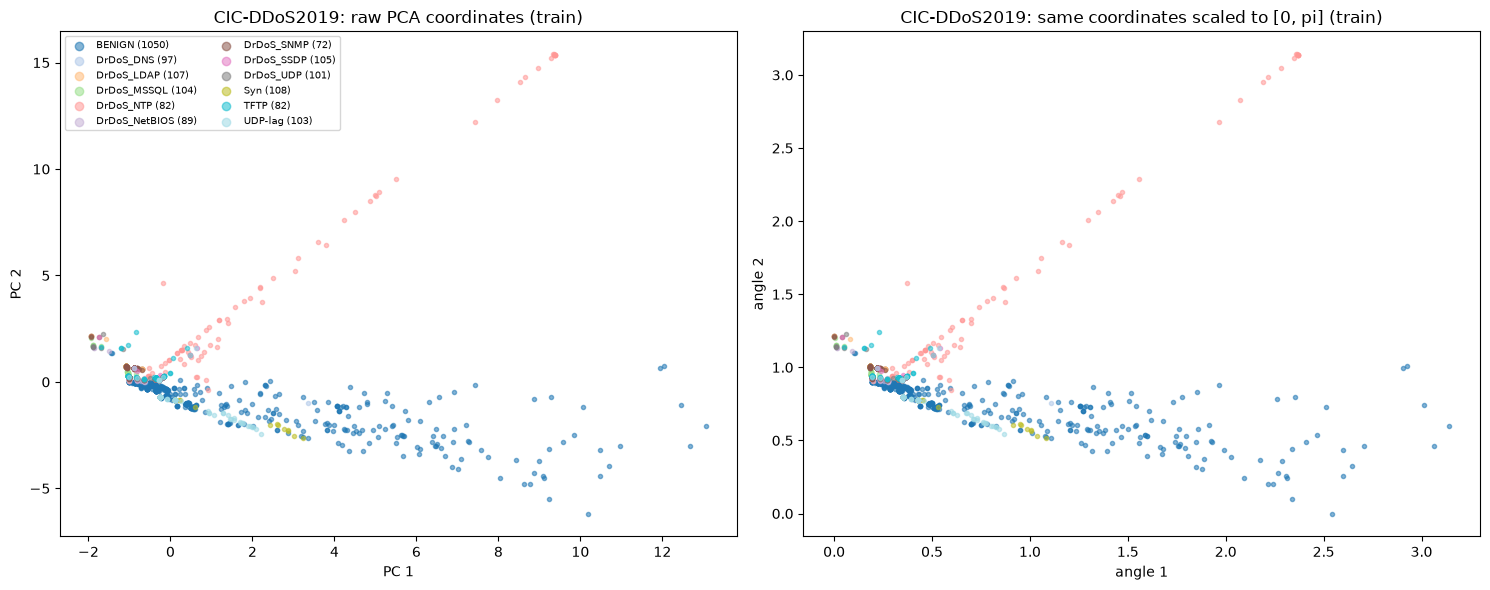

[CIC-DDoS2019] explained variance of the 4 components: [0.266 0.187 0.144 0.112]


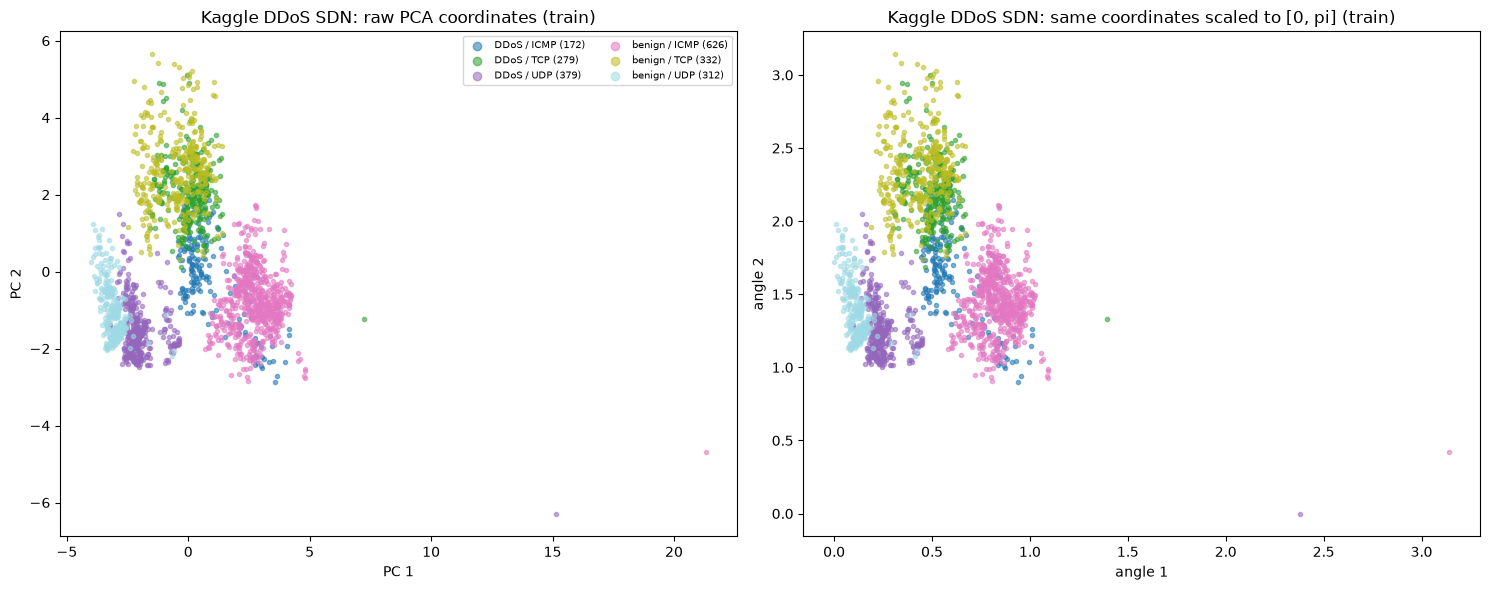

[Kaggle DDoS SDN] explained variance of the 4 components: [0.224 0.133 0.096 0.086]


In [8]:
import matplotlib.cm as cm
def scatter_ds(ds):
    p = PREP[ds]
    if ds == "CIC-DDoS2019":
        labs = np.asarray(p["fam_tr"]); order = sorted(set(labs), key=lambda k: (k != "BENIGN", k))
    else:
        labs = np.array([f"{'DDoS' if y else 'benign'} / {pr}" for y, pr in zip(p["ytr"], p["fam_tr"])]); order = sorted(set(labs))
    cmap = plt.get_cmap("tab20", max(len(order), 2))
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    for ax, M, names, ttl in [(axes[0], p["Ztr"][:, :2], ("PC 1", "PC 2"), "raw PCA coordinates (train)"),
                             (axes[1], p["Ztr4s"][:, :2], ("angle 1", "angle 2"), "same coordinates scaled to [0, pi] (train)")]:
        for i, lab in enumerate(order):
            m = labs == lab
            ax.scatter(M[m, 0], M[m, 1], s=9, alpha=0.55, color=cmap(i), label=f"{lab} ({m.sum()})")
        ax.set_xlabel(names[0]); ax.set_ylabel(names[1]); ax.set_title(f"{ds}: {ttl}")
    axes[0].legend(markerscale=2, fontsize=7, ncol=2)
    plt.tight_layout(); plt.show()
    print(f"[{ds}] explained variance of the 4 components:", np.round(p["evr"], 3))
for ds in DATASETS: scatter_ds(ds)

## 3. The classical baselines and the metrics

All baselines receive **the same angles as the quantum model** (the first `pca` PCA coordinates of the variant). Positive class = attack.

In [9]:
def binmetrics(y, pred):
    pr, rc, f, _ = precision_recall_fscore_support(y, pred, average="binary", zero_division=0)
    return dict(acc=accuracy_score(y, pred), prec=pr, rec=rc, f1=f)

def T(a, dtype=torch.float32): return torch.as_tensor(np.asarray(a), dtype=dtype)

class ClassicalNet(nn.Module):
    """Same head as the C-QNN, but the circuit is replaced by a trainable classical layer Linear(n, n) + tanh (CHOICE: a fair 'no quantum' control)."""
    def __init__(self, n_in, n, m=HIDDEN):
        super().__init__(); self.n = n
        self.pre = nn.Linear(n_in, n); self.l1 = nn.Linear(n, m); self.l2 = nn.Linear(m, 1)
    def forward(self, x): return self.l2(F.relu(self.l1(torch.tanh(self.pre(x))))).squeeze(-1)

def fit_binary(model, Xt, yt, epochs, lr, bs, seed):
    """Adam + binary cross-entropy (Eq. 7; BCEWithLogits = sigmoid + BCE), mini-batches of 5, one loss value per epoch."""
    g = torch.Generator().manual_seed(seed); opt = torch.optim.Adam(model.parameters(), lr)
    N = len(Xt); hist = []
    for ep in range(epochs):
        perm = torch.randperm(N, generator=g); tot = 0.0
        for i in range(0, N, bs):
            idx = perm[i:i + bs]
            loss = F.binary_cross_entropy_with_logits(model(Xt[idx]), yt[idx])
            opt.zero_grad(); loss.backward(); opt.step(); tot += loss.item() * len(idx)
        hist.append(tot / N)
    return hist

@torch.no_grad()
def predict_binary(model, X):
    return (model(T(X)) > 0).numpy().astype(int)

## 4. Quantum components

The paper draws the hybrid model (its Figure 2) but gives no circuit diagram. The sections below define the PennyLane circuits exactly as Eqs. 3-4 and Algorithm 1 describe them and draw them.

* **C-QNN**: `AngleEmbedding(rotation="Y")` -> `StronglyEntanglingLayers` -> `<Z_i>` for every qubit.
* **C-QKM**: a compute-uncompute overlap circuit `|<phi(x)|phi(c)>|^2` = probability of the all-zero outcome after `AngleEmbedding(x)` followed by its adjoint with the centroid `c`.
* **C-QBM**: a circuit Born machine, `StronglyEntanglingLayers` on `|0...0>` with the measurement probabilities `p_theta(s)` as the model distribution.

## Quantum Circuit Architecture

Every gate-based model of the notebook is listed here with the PennyLane QNode that is executed (or that the fast simulator below is asserted to equal), its drawing, qubit count, depth and
number of trainable parameters. Assumptions where the paper is silent: the `StronglyEntanglingLayers` template uses its PennyLane defaults (`Rot` = RZ-RY-RZ rotation per qubit, then CNOTs from qubit `i`
to `(i + r) mod n` with range `r = l mod (n-1) + 1`); the paper's text says "RZ, RX, RZ", which is a loose description of the same three-angle rotation. The hidden width of the classical head is a choice (`HIDDEN`).

C-QNN / CIC-DDoS2019: qubits = 2, depth = 4, trainable circuit parameters = 6, gates = {'RY': 2, 'Rot': 2, 'CNOT': 2}


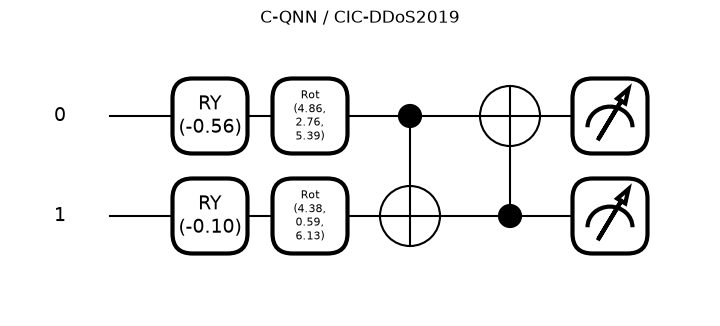

C-QNN / Kaggle DDoS SDN: qubits = 4, depth = 14, trainable circuit parameters = 36, gates = {'RY': 4, 'Rot': 12, 'CNOT': 12}


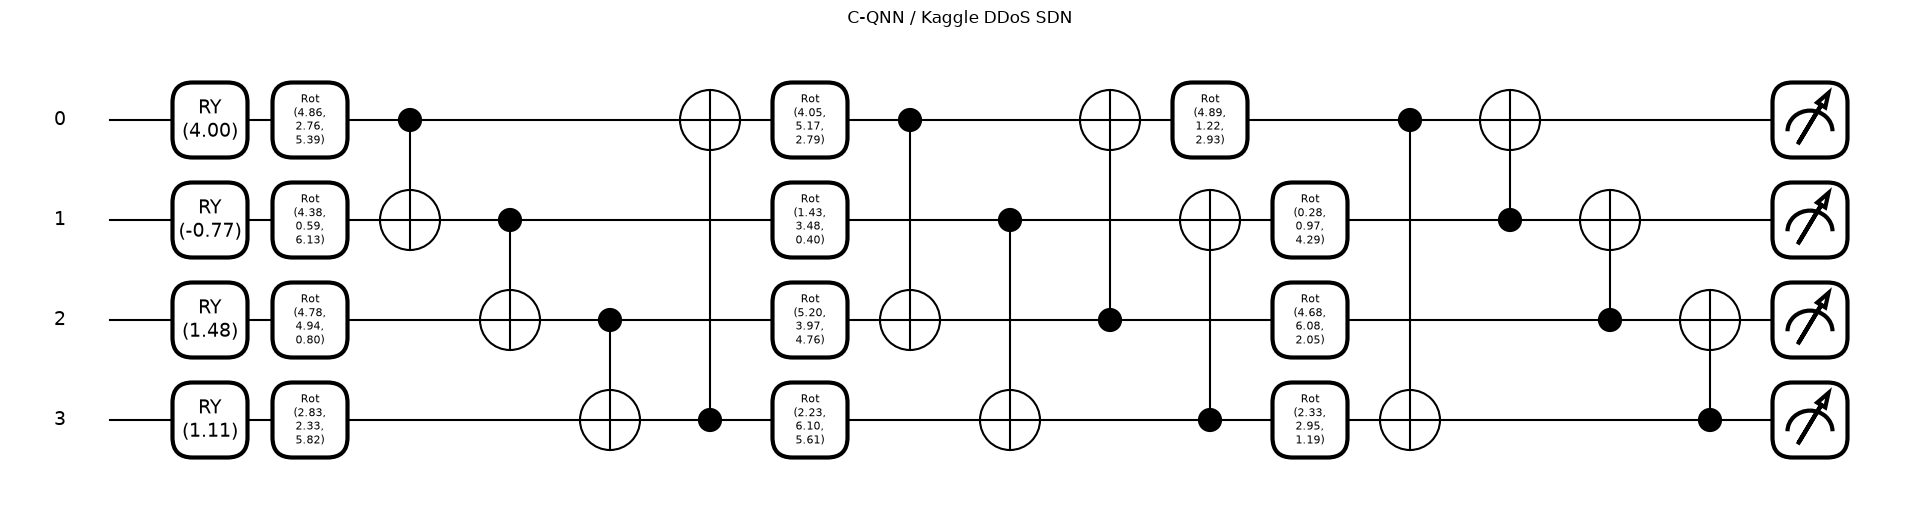

C-QKM overlap / CIC-DDoS2019 (4 qubits): qubits = 4, depth = 2, trainable circuit parameters = 0, gates = {'RY': 4, 'Adjoint(RY)': 4}


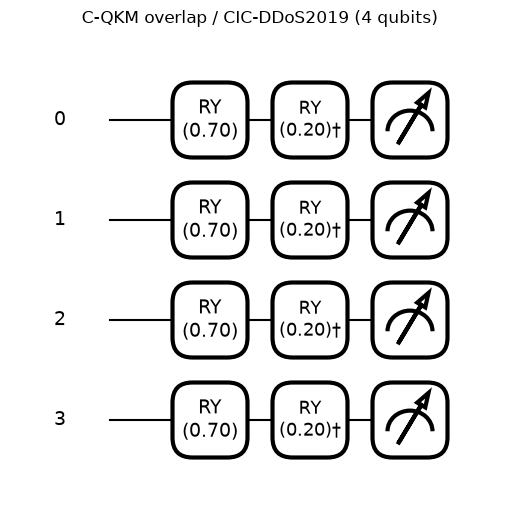

C-QKM overlap / Kaggle DDoS SDN (2 qubits): qubits = 2, depth = 2, trainable circuit parameters = 0, gates = {'RY': 2, 'Adjoint(RY)': 2}


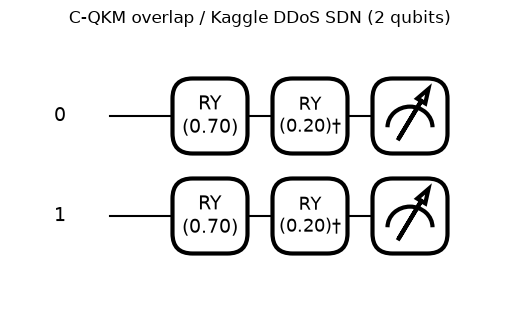

C-QBM Born machine (2 qubits, 2 layers): qubits = 2, depth = 6, trainable circuit parameters = 12, gates = {'Rot': 4, 'CNOT': 4}


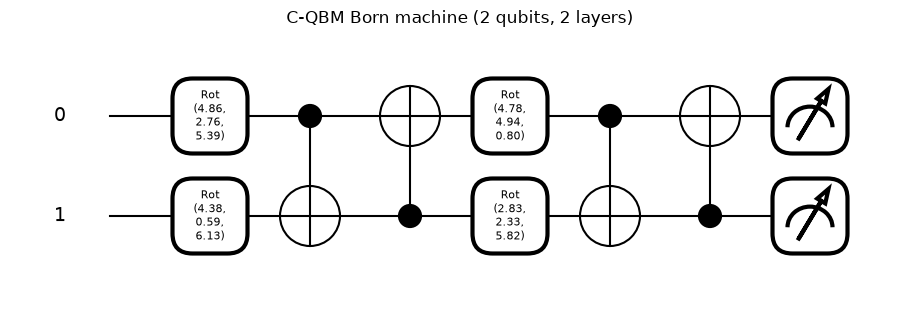

Hybrid C-QNN CIC-DDoS2019: 2 qubits, 1 layer(s), 6 circuit parameters + 65 classical head parameters (Dense(16) + Dense(1)) = 71 trainable parameters
Hybrid C-QNN Kaggle DDoS SDN: 4 qubits, 3 layer(s), 36 circuit parameters + 97 classical head parameters (Dense(16) + Dense(1)) = 133 trainable parameters


In [10]:
def make_qnn_qnode(n):
    dev = qml.device("default.qubit", wires=n)
    @qml.qnode(dev, interface="torch", diff_method="backprop")
    def qnn(inputs, weights):
        qml.AngleEmbedding(inputs, wires=range(n), rotation="Y")                 # Eq. 3: RY(x_i) on qubit i
        qml.StronglyEntanglingLayers(weights, wires=range(n))                    # Eq. 4
        return [qml.expval(qml.PauliZ(i)) for i in range(n)]                     # <Z_i> -> classical head
    return qnn

def make_overlap_qnode(n):
    dev = qml.device("default.qubit", wires=n)
    @qml.qnode(dev)
    def overlap(x, c):
        qml.AngleEmbedding(x, wires=range(n), rotation="Y")                      # |phi(x)>
        qml.adjoint(qml.AngleEmbedding)(c, wires=range(n), rotation="Y")         # <phi(c)|
        return qml.probs(wires=range(n))                                         # P(0...0) = |<phi(c)|phi(x)>|^2
    return overlap

def make_born_qnode(n):
    dev = qml.device("default.qubit", wires=n)
    @qml.qnode(dev, interface="torch", diff_method="backprop")
    def born(weights):
        qml.StronglyEntanglingLayers(weights, wires=range(n))
        return qml.probs(wires=range(n))
    return born

def circuit_stats(qnode, *args):
    s = qml.specs(qnode, level="device")(*args)
    res = s.resources if hasattr(s, "resources") else s["resources"]
    depth = res.depth if hasattr(res, "depth") else res["depth"]
    gates = dict(res.gate_types if hasattr(res, "gate_types") else res["gate_types"])
    return depth, gates

ARCH = {}     # name -> (qnode, args, n_wires, n_trainable_quantum_params, head description)
x_ex = {ds: np.asarray(PREP[ds]["Atr"][0], float) for ds in DATASETS}

for ds in DATASETS:
    n, L = HP[ds]["qnn_qubits"], HP[ds]["qnn_layers"]
    shp = qml.StronglyEntanglingLayers.shape(L, n)
    w_ex = np.random.default_rng(SEED).uniform(0, 2 * np.pi, shp)
    qn = make_qnn_qnode(n); ARCH[f"C-QNN / {ds}"] = (qn, (x_ex[ds], w_ex), n, int(np.prod(shp)))

n = HP["CIC-DDoS2019"]["qkm_qubits"]; ARCH[f"C-QKM overlap / CIC-DDoS2019 ({n} qubits)"] = (make_overlap_qnode(n), (np.full(n, 0.7), np.full(n, 0.2)), n, 0)
n = HP["Kaggle DDoS SDN"]["qkm_qubits"]; ARCH[f"C-QKM overlap / Kaggle DDoS SDN ({n} qubits)"] = (make_overlap_qnode(n), (np.full(n, 0.7), np.full(n, 0.2)), n, 0)
n, LB = 2, 2; shp = qml.StronglyEntanglingLayers.shape(LB, n)
ARCH["C-QBM Born machine (2 qubits, 2 layers)"] = (make_born_qnode(n), (np.random.default_rng(SEED).uniform(0, 2 * np.pi, shp),), n, int(np.prod(shp)))

for name, (qn, args, n, npar) in ARCH.items():
    depth, gates = circuit_stats(qn, *args)
    print(f"{name}: qubits = {n}, depth = {depth}, trainable circuit parameters = {npar}, gates = {gates}")
    fig, ax = qml.draw_mpl(qn, level="device", decimals=2)(*args)
    fig.suptitle(name, y=1.02); plt.show()

for ds in DATASETS:
    n, L = HP[ds]["qnn_qubits"], HP[ds]["qnn_layers"]
    pq_ = L * n * 3; ph = n * HIDDEN + HIDDEN + HIDDEN + 1
    print(f"Hybrid C-QNN {ds}: {n} qubits, {L} layer(s), {pq_} circuit parameters + {ph} classical head parameters (Dense({HIDDEN}) + Dense(1)) = {pq_ + ph} trainable parameters")

### A fast exact simulator, asserted equal to the PennyLane QNode

Training with batch size 5 for 30 epochs needs tens of thousands of circuit evaluations with gradients. PennyLane's QNode costs about 30-100 ms per step on a CPU, so the C-QNN is trained
with a small exact **state-vector simulator written in PyTorch** (build the unitary of the `StronglyEntanglingLayers` from its `Rot` and CNOT gates, apply it to the product state
`RY(x_i)|0>`, read `<Z_i>`). It is not an approximation: the cell below asserts that it reproduces the PennyLane QNode to 1e-9 for random inputs and weights, for both architectures and
for the "2 features on 4 qubits" case, and checks the gradients too. After training, the trained weights are also run through the real QNode (section 6).

In [11]:
def sel_perm(n, r):
    """Permutation matrix of the CNOT ring CNOT(i, (i+r) mod n), i = 0..n-1, applied in this order (wire 0 = most significant bit)."""
    N = 2 ** n; P = np.zeros((N, N))
    for b in range(N):
        bits = [(b >> (n - 1 - i)) & 1 for i in range(n)]
        for i in range(n):
            if bits[i]: bits[(i + r) % n] ^= 1
        P[sum(v << (n - 1 - i) for i, v in enumerate(bits)), b] = 1
    return P

def rot_mats(w):                      # qml.Rot(phi, theta, omega) = RZ(omega) RY(theta) RZ(phi);  w[..., 3] -> [..., 2, 2]
    phi, th, om = w[..., 0], w[..., 1], w[..., 2]
    c, s = torch.cos(th / 2).to(torch.complex128), torch.sin(th / 2).to(torch.complex128)
    e = lambda a: torch.exp(1j * a)
    m00, m01 = e(-(phi + om) / 2) * c, -e((phi - om) / 2) * s
    m10, m11 = e(-(phi - om) / 2) * s, e((phi + om) / 2) * c
    return torch.stack([torch.stack([m00, m01], -1), torch.stack([m10, m11], -1)], -2)

class SELSim:
    def __init__(self, n, L):
        self.n, self.L, self.D = n, L, 2 ** n
        # index form of the permutation: (P @ U)[new] = U[old]
        self.idx = []
        for l in range(L):
            if n > 1:
                P = sel_perm(n, l % (n - 1) + 1); old_for_new = np.argmax(P, axis=1); self.idx.append(torch.as_tensor(old_for_new))
            else: self.idx.append(None)
        bits = np.array([[(b >> (n - 1 - i)) & 1 for i in range(n)] for b in range(self.D)])
        self.zs = torch.tensor(1 - 2 * bits, dtype=torch.float64)
    def unitary(self, w):
        R = rot_mats(w.to(torch.float64)); U = torch.eye(self.D, dtype=torch.complex128)
        for l in range(self.L):
            K = R[l, 0]
            for i in range(1, self.n): K = torch.kron(K, R[l, i])
            U = K @ U
            if self.idx[l] is not None: U = U[self.idx[l]]
        return U
    def expz(self, x, w):
        x = x.to(torch.float64); B = x.shape[0]
        if x.shape[1] < self.n: x = torch.cat([x, torch.zeros(B, self.n - x.shape[1], dtype=x.dtype)], 1)     # missing features -> angle 0 (qubit idle)
        psi = torch.stack([torch.cos(x[:, 0] / 2), torch.sin(x[:, 0] / 2)], -1).to(torch.complex128)
        for i in range(1, self.n):
            q = torch.stack([torch.cos(x[:, i] / 2), torch.sin(x[:, i] / 2)], -1).to(torch.complex128)
            psi = (psi[:, :, None] * q[:, None, :]).reshape(B, -1)
        out = psi @ self.unitary(w).T
        return (out.abs() ** 2) @ self.zs

class HybridQNN(nn.Module):
    """AngleEmbedding(RY) -> StronglyEntanglingLayers -> <Z_i> -> Dense(m)+ReLU -> Dense(1) (logit; the sigmoid sits in the loss / threshold)."""
    def __init__(self, n, L, m=HIDDEN):
        super().__init__(); self.n, self.L = n, L; self.sim = SELSim(n, L)
        self.w = nn.Parameter(torch.rand(L, n, 3, dtype=torch.float64) * 2 * math.pi)     # uniform [0, 2 pi): PennyLane / Keras layer default
        self.l1 = nn.Linear(n, m); self.l2 = nn.Linear(m, 1)
    def quantum(self, x): return self.sim.expz(x, self.w)
    def forward(self, x): return self.l2(F.relu(self.l1(self.quantum(x).float()))).squeeze(-1)

# ---- equivalence assertions against the real PennyLane QNode ----
g = torch.Generator().manual_seed(SEED)
for n, L, nfeat in [(2, 1, 2), (4, 3, 4), (4, 3, 2)]:
    qn = make_qnn_qnode(n); sim = SELSim(n, L)
    w = (torch.rand(L, n, 3, generator=g, dtype=torch.float64) * 2 * math.pi).requires_grad_(True)
    x = torch.randn(9, nfeat, generator=g, dtype=torch.float64)
    z_qnode = torch.stack(qn(x, w), -1); z_sim = sim.expz(x, w)
    err = (z_qnode - z_sim).abs().max().item()
    g1 = torch.autograd.grad(z_qnode.sum(), w, retain_graph=True)[0]; g2 = torch.autograd.grad(z_sim.sum(), w)[0]
    gerr = (g1 - g2).abs().max().item()
    assert err < 1e-9 and gerr < 1e-9, (n, L, err, gerr)
    print(f"n={n}, L={L}, features={nfeat}: max |<Z>_QNode - <Z>_simulator| = {err:.2e}, max gradient difference = {gerr:.2e}  -> equal")
print("The fast simulator reproduces the PennyLane QNode (values and gradients).")

n=2, L=1, features=2: max |<Z>_QNode - <Z>_simulator| = 3.33e-16, max gradient difference = 1.87e-15  -> equal


n=4, L=3, features=4: max |<Z>_QNode - <Z>_simulator| = 5.27e-16, max gradient difference = 2.22e-15  -> equal


n=4, L=3, features=2: max |<Z>_QNode - <Z>_simulator| = 6.66e-16, max gradient difference = 3.33e-15  -> equal
The fast simulator reproduces the PennyLane QNode (values and gradients).


## 5. Training the models

### 5.1 C-QNN and its classical control

`train_qnn` trains the hybrid network (Adam, binary cross-entropy, batch size 5, `EPOCHS` epochs, learning rate from Table 3). The classical control is the same head with a trainable
`Linear(n, n)` + tanh in place of the circuit. Random forest and RBF-SVM use the same angles.

In [12]:
def train_qnn(P, ds, seed, quantum=True):
    hp = HP[ds]; n, L = hp["qnn_qubits"], hp["qnn_layers"]; k = P["Atr"].shape[1]
    torch.manual_seed(seed)
    model = HybridQNN(n, L) if quantum else ClassicalNet(k, n)
    t0 = time.perf_counter()
    hist = fit_binary(model, T(P["Atr"]), T(P["ytr"]), EPOCHS, hp["qnn_lr"], BATCH, seed)
    pred = predict_binary(model, P["Ate"]); secs = time.perf_counter() - t0
    return model, hist, pred, secs

def run_baselines(P, seed):
    out = {}
    for name, clf in [("Random forest (same inputs)", RandomForestClassifier(100, random_state=seed, n_jobs=1)), ("SVC rbf (same inputs)", SVC(kernel="rbf", C=1.0, random_state=seed))]:
        t0 = time.perf_counter(); clf.fit(P["Atr"], P["ytr"]); pred = clf.predict(P["Ate"]); out[name] = (pred, time.perf_counter() - t0)
    return out

### 5.2 C-QKM: quantum k-means

Two clusters. The distance between a flow and a centroid is `1 - P(0...0)` of the overlap circuit above (angles = raw PCA coordinates, as for the C-QNN); the first centroid is a random flow, the second the flow
farthest from it, and each iteration assigns every flow to the nearest centroid and moves the centroid to the mean of its flows (the classical update step of "quantum-assisted" k-means). Each cluster is
named benign or attack by the majority label of its training flows. ARI, NMI and the silhouette (Euclidean, on up to 2,000 test flows) compare the clusters of the **test** flows with the true classes.

In [13]:
def closed_form_overlap(x, c): return np.prod(np.cos((x - c) / 2) ** 2, axis=-1)

# the overlap circuit equals the closed form (assertion)
_ov = make_overlap_qnode(4); _x = np.random.default_rng(1).uniform(-2, 2, (6, 4)); _c = np.random.default_rng(2).uniform(-2, 2, 4)
assert np.allclose(np.asarray(_ov(_x, _c))[:, 0], closed_form_overlap(_x, _c), atol=1e-12)
print("overlap circuit == prod_i cos^2((x_i - c_i)/2): asserted")

def qdist(ov, Z, c): return 1.0 - np.asarray(ov(Z, c))[:, 0]

def run_qkm(P, ds, seed, scaled=False):
    """scaled=False: raw PCA coordinates as angles (primary, like the C-QNN); scaled=True: coordinates min-max scaled to [0, pi]."""
    n = HP[ds]["qkm_qubits"]; ov = make_overlap_qnode(n)
    Ztr, Zte = (P["Ztr4s"][:, :n], P["Zte4s"][:, :n]) if scaled else (P["Ztr"][:, :n], P["Zte"][:, :n]); ytr, yte = P["ytr"], P["yte"]
    t0 = time.perf_counter(); r = np.random.default_rng(seed)
    c0 = Ztr[r.integers(len(Ztr))]; c1 = Ztr[np.argmax(qdist(ov, Ztr, c0))]; C = np.stack([c0, c1])      # farthest-point initialisation
    for it in range(KMEANS_ITERS):
        a = np.stack([qdist(ov, Ztr, C[j]) for j in range(2)], 1).argmin(1)
        newC = np.stack([Ztr[a == j].mean(0) if (a == j).any() else C[j] for j in range(2)])
        if np.allclose(newC, C): break
        C = newC
    a_tr = np.stack([qdist(ov, Ztr, C[j]) for j in range(2)], 1).argmin(1)
    cl2lab = {j: int(round(ytr[a_tr == j].mean())) if (a_tr == j).any() else j for j in range(2)}
    a_te = np.stack([qdist(ov, Zte, C[j]) for j in range(2)], 1).argmin(1)
    pred = np.array([cl2lab[j] for j in a_te])
    m = binmetrics(yte, pred)
    m["ari"] = adjusted_rand_score(yte, a_te); m["nmi"] = normalized_mutual_info_score(yte, a_te)
    sub = np.random.default_rng(seed).choice(len(Zte), min(2000, len(Zte)), replace=False)
    m["sil"] = silhouette_score(Zte[sub], a_te[sub]) if len(set(a_te[sub])) > 1 else float("nan")
    return m, pred, time.perf_counter() - t0

overlap circuit == prod_i cos^2((x_i - c_i)/2): asserted


### 5.3 C-QBM: circuit Born machine as an anomaly detector

The Born machine `p_theta(s) = |<s|U(theta)|0>|^2` on 2 qubits is trained to reproduce the distribution of the **benign** training flows, each flow reduced to two bits (first two PCA components above / below their
training medians). A flow is called an attack when the model gives its bit pattern a probability below a threshold; the threshold is the one that maximises the training accuracy (only four values are possible). This is
our reading of "quantum probability distributions for identifying anomalies"; the paper gives no further detail, and a 2-bit summary cannot be expected to separate the classes well.

In [14]:
def run_qbm(P, ds, seed):
    n, LB = HP[ds]["qbm_qubits"], 2; lr = HP[ds]["qbm_lr"]
    Ztr, Zte = P["Ztr"][:, :n], P["Zte"][:, :n]; ytr, yte = P["ytr"], P["yte"]
    med = np.median(Ztr, 0); w2 = 2 ** np.arange(n - 1, -1, -1)
    state = lambda Z: ((Z > med).astype(int) * w2).sum(1)
    s_tr, s_te = state(Ztr), state(Zte); ben = s_tr[ytr == 0]
    born = make_born_qnode(n); torch.manual_seed(seed)
    w = (torch.rand(*qml.StronglyEntanglingLayers.shape(LB, n), dtype=torch.float64) * 2 * math.pi).requires_grad_(True)
    opt = torch.optim.Adam([w], lr); gen = np.random.default_rng(seed); t0 = time.perf_counter()
    for ep in range(EPOCHS_QBM):
        perm = gen.permutation(len(ben))
        for i in range(0, len(ben), BORN_BATCH):
            q = torch.tensor(np.bincount(ben[perm[i:i + BORN_BATCH]], minlength=2 ** n) / len(perm[i:i + BORN_BATCH]))
            loss = -(q * torch.log(born(w) + 1e-9)).sum()                     # cross-entropy between the batch distribution and p_theta
            opt.zero_grad(); loss.backward(); opt.step()
    p = born(w).detach().numpy()
    cands = [-1.0] + sorted(set(np.round(p, 12)))
    accs = [accuracy_score(ytr, (p[s_tr] <= t).astype(int)) for t in cands]
    thr = cands[int(np.argmax(accs))]                                          # threshold chosen on the TRAINING split only
    pred = (p[s_te] <= thr).astype(int)
    return binmetrics(yte, pred), pred, time.perf_counter() - t0, p

## 6. Running everything

For every seed and data set the notebook trains the `paper` pipeline (C-QNN, classical control, baselines, C-QKM, C-QBM). For the first seed it also runs the ablation variants (signed log, [0, pi] angles,
the literal "PCA 2 on 4 qubits" row of Table 3, no identifier columns). Runtime is printed per run.

In [15]:
ROWS, LOSS, PRED, MODELS = [], {}, {}, {}
def add(ds, var, model, seed, m, secs, **extra):
    ROWS.append(dict(dataset=ds, variant=var, model=model, seed=seed, secs=secs, **m, **extra))

T_START = time.perf_counter()
for seed in SEEDS:
    for ds in DATASETS:
        for vname in VARIANTS[ds]:
            if vname != "paper" and seed != SEEDS[0]: continue                 # ablations only for the first seed
            P = prepare(ds, seed, vname); yte = P["yte"]
            t0 = time.perf_counter()
            model, hist, pred, secs = train_qnn(P, ds, seed, quantum=True)
            add(ds, vname, "C-QNN", seed, binmetrics(yte, pred), secs); LOSS[(ds, vname, seed)] = hist; PRED[(ds, vname, "C-QNN", seed)] = pred
            MODELS[(ds, vname, seed)] = (model, P)
            _, _, pred_c, secs_c = train_qnn(P, ds, seed, quantum=False)
            add(ds, vname, "Classical net (same head)", seed, binmetrics(yte, pred_c), secs_c)
            for name, (pr, sc_) in run_baselines(P, seed).items(): add(ds, vname, name, seed, binmetrics(yte, pr), sc_)
            rf_all = RandomForestClassifier(100, random_state=seed, n_jobs=1).fit(P["Xtr"], P["ytr"])
            add(ds, vname, "Random forest (all features)", seed, binmetrics(yte, rf_all.predict(P["Xte"])), 0.0)
            for mname, sc_flag in [("C-QKM", False), ("C-QKM ([0,pi] angles)", True)]:
                m, pred_k, secs_k = run_qkm(P, ds, seed, scaled=sc_flag)
                add(ds, vname, mname, seed, {k: m[k] for k in ("acc", "prec", "rec", "f1")}, secs_k, ari=m["ari"], nmi=m["nmi"], sil=m["sil"]); PRED[(ds, vname, mname, seed)] = pred_k
            m, pred_b, secs_b, _ = run_qbm(P, ds, seed); add(ds, vname, "C-QBM", seed, m, secs_b); PRED[(ds, vname, "C-QBM", seed)] = pred_b
            last = {r_["model"]: r_ for r_ in ROWS[-8:]}
            print(f"seed {seed} | {ds:16s} | {vname:12s} | C-QNN acc {last['C-QNN']['acc']:.4f} (F1 {last['C-QNN']['f1']:.3f}, {last['C-QNN']['secs']:.0f} s) | control {last['Classical net (same head)']['acc']:.4f} "
                  f"| RF {last['Random forest (same inputs)']['acc']:.4f} | C-QKM {last['C-QKM']['acc']:.4f} | C-QBM {last['C-QBM']['acc']:.4f} | total {time.perf_counter() - T_START:.0f} s")
RES = pd.DataFrame(ROWS)
print(f"\nAll runs finished in {(time.perf_counter() - T_START) / 60:.1f} minutes.")

seed 42 | CIC-DDoS2019     | paper        | C-QNN acc 0.9389 (F1 0.939, 177 s) | control 0.9511 | RF 0.9900 | C-QKM 0.5156 | C-QBM 0.6800 | total 292 s


seed 42 | CIC-DDoS2019     | log1p        | C-QNN acc 0.9089 (F1 0.909, 189 s) | control 0.9656 | RF 0.9933 | C-QKM 0.5911 | C-QBM 0.7656 | total 622 s


seed 42 | CIC-DDoS2019     | log1p+[0,pi] | C-QNN acc 0.9322 (F1 0.935, 226 s) | control 0.9700 | RF 0.9933 | C-QKM 0.5911 | C-QBM 0.7656 | total 931 s


seed 42 | Kaggle DDoS SDN  | paper        | C-QNN acc 0.8589 (F1 0.818, 250 s) | control 0.8867 | RF 0.9044 | C-QKM 0.6044 | C-QBM 0.6022 | total 1265 s


seed 42 | Kaggle DDoS SDN  | [0,pi]       | C-QNN acc 0.7633 (F1 0.735, 271 s) | control 0.8667 | RF 0.9044 | C-QKM 0.6044 | C-QBM 0.6022 | total 1653 s


...

seed 42 | Kaggle DDoS SDN  | no_ids       | C-QNN acc 0.8544 (F1 0.817, 165 s) | control 0.8833 | RF 0.9200 | C-QKM 0.6044 | C-QBM 0.6044 | total 2239 s


seed 43 | CIC-DDoS2019     | paper        | C-QNN acc 0.8944 (F1 0.893, 89 s) | control 0.9633 | RF 0.9789 | C-QKM 0.4933 | C-QBM 0.8000 | total 2379 s


seed 43 | Kaggle DDoS SDN  | paper        | C-QNN acc 0.8278 (F1 0.776, 176 s) | control 0.8689 | RF 0.9044 | C-QKM 0.6056 | C-QBM 0.6311 | total 2615 s


seed 44 | CIC-DDoS2019     | paper        | C-QNN acc 0.9233 (F1 0.926, 127 s) | control 0.9444 | RF 0.9844 | C-QKM 0.5233 | C-QBM 0.8033 | total 2829 s


seed 44 | Kaggle DDoS SDN  | paper        | C-QNN acc 0.8544 (F1 0.809, 193 s) | control 0.8989 | RF 0.9156 | C-QKM 0.6133 | C-QBM 0.6133 | total 3102 s

All runs finished in 51.7 minutes.


### 6.1 The trained C-QNN through the real PennyLane QNode

The trained weights of the primary C-QNN of the first seed are now run through the **real PennyLane QNode** on the test flows; the expectation values must equal the simulator's and the final
predictions must be identical.

In [16]:
for ds in DATASETS:
    model, P = MODELS[(ds, "paper", SEEDS[0])]
    n = HP[ds]["qnn_qubits"]; qn = make_qnn_qnode(n)
    X = T(P["Ate"], torch.float64)[:400]
    with torch.no_grad():
        z_q = torch.stack(qn(X, model.w.detach()), -1); z_s = model.quantum(X)
        pred_q = (model.l2(F.relu(model.l1(z_q.float()))).squeeze(-1) > 0).numpy().astype(int)
        pred_s = predict_binary(model, P["Ate"][:400])
    err = (z_q - z_s).abs().max().item()
    assert err < 1e-9 and (pred_q == pred_s).all()
    print(f"{ds}: trained weights through the PennyLane QNode -> max |dz| = {err:.1e}, predictions identical on {len(pred_q)} test flows, test accuracy of these = {accuracy_score(P['yte'][:400], pred_q):.4f}")

CIC-DDoS2019: trained weights through the PennyLane QNode -> max |dz| = 5.6e-16, predictions identical on 400 test flows, test accuracy of these = 0.9425
Kaggle DDoS SDN: trained weights through the PennyLane QNode -> max |dz| = 7.8e-16, predictions identical on 400 test flows, test accuracy of these = 0.8475


## 7. Results

### 7.1 Main table (the paper's pipeline, mean +- std over seeds)

In [17]:
def fmt(g, col):
    m, s = g[col].mean(), g[col].std(ddof=0)
    return f"{m:.4f}" + (f" +- {s:.4f}" if len(g) > 1 else "")

main = RES[RES["variant"] == "paper"]
order = ["C-QNN", "Classical net (same head)", "Random forest (same inputs)", "SVC rbf (same inputs)", "Random forest (all features)", "C-QKM", "C-QKM ([0,pi] angles)", "C-QBM"]
tab = []
for ds in DATASETS:
    for mdl in order:
        g = main[(main["dataset"] == ds) & (main["model"] == mdl)]
        if len(g): tab.append({"dataset": ds, "model": mdl, "accuracy": fmt(g, "acc"), "precision": fmt(g, "prec"), "recall": fmt(g, "rec"), "F1": fmt(g, "f1"), "time s": f"{g['secs'].mean():.0f}", "runs": len(g)})
MAIN_TABLE = pd.DataFrame(tab); display(MAIN_TABLE) if "display" in globals() else print(MAIN_TABLE.to_string(index=False))

        dataset                        model         accuracy        precision           recall               F1 time s  runs
   CIC-DDoS2019                        C-QNN 0.9189 +- 0.0184 0.9116 +- 0.0189 0.9281 +- 0.0320 0.9195 +- 0.0192    131     3
   CIC-DDoS2019    Classical net (same head) 0.9530 +- 0.0078 0.9517 +- 0.0187 0.9548 +- 0.0052 0.9531 +- 0.0073     69     3
   CIC-DDoS2019  Random forest (same inputs) 0.9844 +- 0.0045 0.9809 +- 0.0054 0.9881 +- 0.0069 0.9845 +- 0.0045      1     3
   CIC-DDoS2019        SVC rbf (same inputs) 0.8626 +- 0.0132 0.9628 +- 0.0126 0.7548 +- 0.0337 0.8456 +- 0.0183      1     3
   CIC-DDoS2019 Random forest (all features) 0.9974 +- 0.0023 0.9985 +- 0.0011 0.9963 +- 0.0038 0.9974 +- 0.0023      0     3
   CIC-DDoS2019                        C-QKM 0.5107 +- 0.0127 0.5267 +- 0.0599 0.3756 +- 0.4117 0.3197 +- 0.2462      3     3
   CIC-DDoS2019        C-QKM ([0,pi] angles) 0.5181 +- 0.0171 0.4836 +- 0.3801 0.3296 +- 0.4459 0.2442 +- 0.3066      

### 7.2 Ablations and variants (first seed)

In [18]:
abl = RES[RES["seed"] == SEEDS[0]].pivot_table(index=["dataset", "variant"], columns="model", values="acc")[[c for c in order if c in RES["model"].unique()]]
print("Test accuracy, first seed:"); print(abl.round(4).to_string())

Test accuracy, first seed:
model                          C-QNN  Classical net (same head)  Random forest (same inputs)  SVC rbf (same inputs)  Random forest (all features)   C-QKM  C-QKM ([0,pi] angles)   C-QBM
dataset         variant                                                                                                                                                                 
CIC-DDoS2019    log1p         0.9089                     0.9656                       0.9933                 0.9811                        1.0000  0.5911                 0.5189  0.7656
                log1p+[0,pi]  0.9322                     0.9700                       0.9933                 0.9800                        1.0000  0.5911                 0.5189  0.7656
                paper         0.9389                     0.9511                       0.9900                 0.8789                        1.0000  0.5156                 0.5411  0.6800
Kaggle DDoS SDN Table3 PCA2   0.8111            

### 7.3 Loss curves and confusion matrices of the primary C-QNN (first seed)

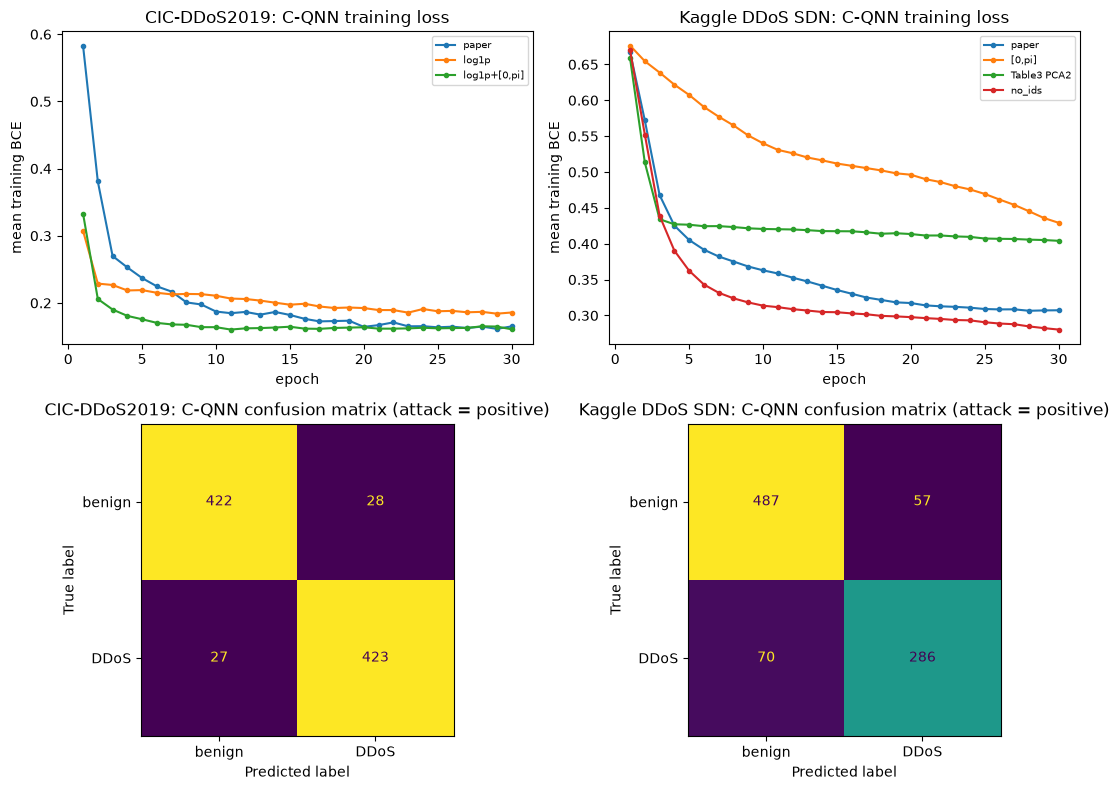

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for j, ds in enumerate(DATASETS):
    ax = axes[0, j]
    for vname in VARIANTS[ds]:
        if (ds, vname, SEEDS[0]) in LOSS: ax.plot(range(1, EPOCHS + 1), LOSS[(ds, vname, SEEDS[0])], marker="o", ms=3, label=vname)
    ax.set_xlabel("epoch"); ax.set_ylabel("mean training BCE"); ax.set_title(f"{ds}: C-QNN training loss"); ax.legend(fontsize=7)
    P = MODELS[(ds, "paper", SEEDS[0])][1]; pred = PRED[(ds, "paper", "C-QNN", SEEDS[0])]
    cm_ = confusion_matrix(P["yte"], pred, labels=[0, 1])
    ConfusionMatrixDisplay(cm_, display_labels=["benign", "DDoS"]).plot(ax=axes[1, j], colorbar=False)
    axes[1, j].set_title(f"{ds}: C-QNN confusion matrix (attack = positive)")
plt.tight_layout(); plt.show()

### 7.4 The paper's Figures 6-7 redrawn: three models side by side with the paper

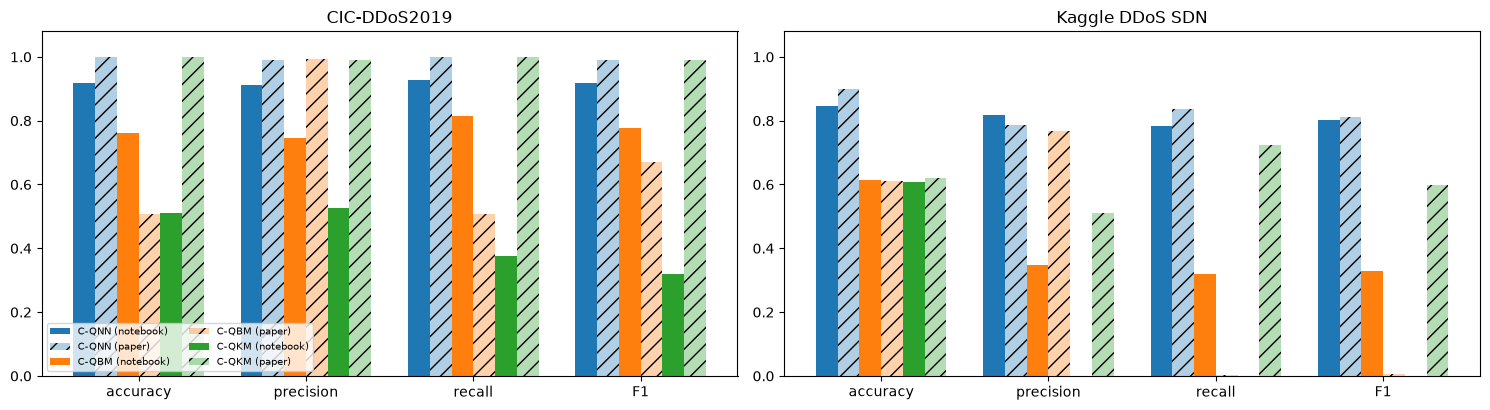

In [20]:
PAPER = {
    "CIC-DDoS2019": {"C-QNN": dict(acc=0.9989, prec=0.99, rec=0.9994, f1=0.99),
                     "C-QBM": dict(acc=0.5062, prec=0.9933, rec=0.5068, f1=0.6712),
                     "C-QKM": dict(acc=0.9988, prec=0.99, rec=0.9988, f1=0.99, ari=0.9075, nmi=0.8431, sil=0.9772)},
    "Kaggle DDoS SDN": {"C-QNN": dict(acc=0.8996, prec=0.7855, rec=0.8364, f1=0.8109),
                        "C-QBM": dict(acc=0.6108, prec=0.7692, rec=0.0039, f1=0.0065),
                        "C-QKM": dict(acc=0.6219, prec=0.5107, rec=0.7247, f1=0.5992, ari=0.0588, nmi=0.05746, sil=0.1791)},
}
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
mets = ["acc", "prec", "rec", "f1"]; width = 0.13
for ax, ds in zip(axes, DATASETS):
    for i, mdl in enumerate(["C-QNN", "C-QBM", "C-QKM"]):
        g = main[(main["dataset"] == ds) & (main["model"] == mdl)]
        ours = [g[m].mean() for m in mets]; theirs = [PAPER[ds][mdl][m] for m in mets]
        ax.bar(np.arange(4) + (2 * i) * width, ours, width, label=f"{mdl} (notebook)", color=plt.cm.tab10(i))
        ax.bar(np.arange(4) + (2 * i + 1) * width, theirs, width, label=f"{mdl} (paper)", color=plt.cm.tab10(i), alpha=0.35, hatch="//")
    ax.set_xticks(np.arange(4) + 2.5 * width); ax.set_xticklabels(["accuracy", "precision", "recall", "F1"]); ax.set_ylim(0, 1.08); ax.set_title(ds)
axes[0].legend(fontsize=7, ncol=2, loc="lower left")
plt.tight_layout(); plt.show()

## 8. Side by side with the paper

Verdict rule (project convention): **reproduced** if the notebook value is within 0.02 of the paper's value (accuracy, precision, recall, F1, ARI, NMI, silhouette); otherwise **not reached**
(notebook lower) or **exceeded** (notebook higher), with the gap. The notebook value is the mean over seeds of the `paper` pipeline.

In [21]:
TOL = 0.02
names = {"acc": "accuracy", "prec": "precision", "rec": "recall", "f1": "F1", "ari": "ARI", "nmi": "NMI", "sil": "silhouette"}
rows = []
for ds in DATASETS:
    for mdl, vals in PAPER[ds].items():
        g = main[(main["dataset"] == ds) & (main["model"] == mdl)]
        for k, pv in vals.items():
            nv = float(g[k].mean()); d = nv - pv
            v = "reproduced" if abs(d) <= TOL else (f"exceeded (+{d:.3f})" if d > 0 else f"not reached ({d:.3f})")
            rows.append({"data set": ds, "model": mdl, "metric": names[k], "paper": pv, "notebook": round(nv, 4), "verdict": v})
CMP = pd.DataFrame(rows)
for ds in DATASETS:
    a = {m: float(main[(main["dataset"] == ds) & (main["model"] == m)]["acc"].mean()) for m in ["C-QNN", "C-QBM", "C-QKM"]}
    best = max(a, key=a.get)
    rows.append({"data set": ds, "model": "ordering", "metric": "C-QNN has the best accuracy of the three", "paper": "yes", "notebook": f"best = {best} ({a[best]:.4f}); C-QNN {a['C-QNN']:.4f}",
                 "verdict": "reproduced" if best == "C-QNN" else "not reached"})
CMP = pd.DataFrame(rows)
pd.set_option("display.width", 200, "display.max_colwidth", 80)
print(CMP.to_string(index=False))
print("\nVerdict counts:"); print(CMP["verdict"].str.replace(r" \(.*\)", "", regex=True).value_counts().to_string())

       data set    model                                   metric    paper                            notebook              verdict
   CIC-DDoS2019    C-QNN                                 accuracy   0.9989                              0.9189 not reached (-0.080)
   CIC-DDoS2019    C-QNN                                precision     0.99                              0.9116 not reached (-0.078)
   CIC-DDoS2019    C-QNN                                   recall   0.9994                              0.9281 not reached (-0.071)
   CIC-DDoS2019    C-QNN                                       F1     0.99                              0.9195 not reached (-0.071)
   CIC-DDoS2019    C-QBM                                 accuracy   0.5062                              0.7611    exceeded (+0.255)
   CIC-DDoS2019    C-QBM                                precision   0.9933                              0.7457 not reached (-0.248)
   CIC-DDoS2019    C-QBM                                   recall   0.5068  

In [22]:
# Sanity check of the paper's own numbers (Table 5, C-QKM on CIC-DDoS2019): accuracy 0.9988 and ARI 0.9075 should not go together.
yb = np.repeat([0, 1], 5000); err = 1 - 0.9988
flip = np.random.default_rng(0).choice(len(yb), int(round(err * len(yb))), replace=False)
yc = yb.copy(); yc[flip] ^= 1
print(f"Two balanced classes, 99.88 % of flows in the right cluster -> ARI = {adjusted_rand_score(yb, yc):.4f}, NMI = {normalized_mutual_info_score(yb, yc):.4f}  (paper: ARI 0.9075, NMI 0.8431)")
# F1 implied by the paper's precision / recall
for ds, mdl, p_, r_, f_ in [("CIC-DDoS2019", "C-QBM", 0.9933, 0.5068, 0.6712), ("Kaggle", "C-QNN", 0.7855, 0.8364, 0.8109), ("Kaggle", "C-QKM", 0.5107, 0.7247, 0.5992), ("Kaggle", "C-QBM", 0.7692, 0.0039, 0.0065)]:
    print(f"{ds:13s} {mdl}: 2PR/(P+R) = {2 * p_ * r_ / (p_ + r_):.4f}  vs reported F1 {f_}")

Two balanced classes, 99.88 % of flows in the right cluster -> ARI = 0.9952, NMI = 0.9866  (paper: ARI 0.9075, NMI 0.8431)
CIC-DDoS2019  C-QBM: 2PR/(P+R) = 0.6712  vs reported F1 0.6712
Kaggle        C-QNN: 2PR/(P+R) = 0.8102  vs reported F1 0.8109
Kaggle        C-QKM: 2PR/(P+R) = 0.5992  vs reported F1 0.5992
Kaggle        C-QBM: 2PR/(P+R) = 0.0078  vs reported F1 0.0065


## 9. Reading the paper critically

* **The two tables are not mutually consistent.** For C-QKM on CIC-DDoS2019 an accuracy of 99.88 % on two balanced classes implies an ARI of about 0.995, not 0.9075 (cell above); the C-QBM row (precision 0.9933, recall 0.5068, accuracy 0.5062) cannot come from a
  balanced test set either. Table 3 gives "PCA components = 2" for the Kaggle C-QNN while using 4 qubits, and the text says four components. Precision "0.99" and F1 "0.99" are printed with two digits only.
* **The data are not vehicular.** Both data sets are generic: the Kaggle set comes from a Mininet/Ryu SDN with 10 hosts and no mobility, CIC-DDoS2019 from a wired testbed. The Mininet-WiFi vehicular test bed (Algorithm 2, Table 4) is described, but no
  result from it is given, so the title's "software-defined vehicular networks" is not tested by any reported number. This notebook cannot test it either.
* **The circuit does not explain the numbers; a classical layer does at least as well.** (Numbers of the full run stored in this notebook, 3 seeds, section 7.1.) CIC-DDoS2019: C-QNN 0.919 +- 0.018 against 0.9989 in the paper; the same head with a classical layer
  instead of the 6-parameter circuit reaches 0.953, a random forest on the same two coordinates 0.984 and a random forest on all 14 features 0.997. Kaggle DDoS SDN: C-QNN 0.847 against 0.8996; classical control 0.885, random forest 0.908,
  RBF-SVM 0.896, random forest on all features 0.990. The paper has no classical baseline, so "quantum advantage" cannot be read from it; and the paper's 90 % on the Kaggle data is far below what a plain random forest reaches on that data set.
* **Pre-processing and angle range matter.** The CIC features have extreme tails (negative header lengths of -2e11). A signed `log1p` lifts the RBF-SVM from 0.879 to 0.981 and the classical network, but not the C-QNN (0.939 -> 0.909, first seed, section 7.2).
  Raw PCA coordinates are used directly as rotation angles, as in the paper; scaling them to [0, pi] lowered the Kaggle C-QNN from 0.859 to 0.763, and the literal Table 3 setting (2 components on 4 qubits) gave 0.811. The paper states none of this.
* **Possible shortcuts in the Kaggle data.** `dt` (a time stamp), the IP octets and the switch id identify the simulation run and traffic generator. Removing them barely changes the C-QNN (0.854 against 0.859, first seed) and leaves the random forest on all features at 0.99,
  so the data set is easy for classical models either way.
* **C-QKM does not separate benign from attack here.** Two unsupervised clusters of four (CIC) or two (Kaggle) principal components do not line up with the benign / attack split: accuracy is about chance on CIC-DDoS2019 (ARI close to 0) and on the Kaggle set both clusters are
  named "benign", so every flow is predicted benign (precision and recall 0). The paper reports 99.88 % for the same method on CIC-DDoS2019; with 11 attack families inside one class it is hard to see how two clusters could achieve this, which is one more reason to doubt Table 5.
  Our C-QKM and C-QBM are reconstructions of under-specified methods, so these two rows say something about our reading as much as about the paper.
* **The ordering claim holds but is weak.** The C-QNN is the best of the three quantum models on both data sets, as claimed, but the other two are close to chance here, and both lose to classical models trained on the same inputs.
* **Sampling.** The paper trains on whole data sets; here a seeded sample of 3,000 flows per data set is used (the batch-size-5 loop makes each training run take minutes on a CPU), so the C-QNN sees far less data than in the paper. `N_CIC` and `N_KAG` are configurable.

## 10. Exercises

1. Set `HIDDEN` to 4 and to 64 and compare the C-QNN with the classical control. Does the quantum layer matter more when the head is small?
2. Replace `StronglyEntanglingLayers` by `BasicEntanglerLayers` or remove the CNOTs (product circuit) in `make_qnn_qnode` and in `SELSim` and re-run the equivalence cell. What does the circuit contribute without entanglement?
3. Run the CIC-DDoS2019 C-QNN with 3 and 4 qubits (set `qnn_qubits` and the variant's `pca`) and with 2 or 3 layers. At which size does it catch the random forest?
4. Train on CIC-DDoS2019 and test on the Kaggle data (or the other way round) after mapping both to the same number of PCA components. Which model generalises?
5. Replace the quantum distance in `run_qkm` by the Euclidean distance (scikit-learn `KMeans`, k = 2) on the same coordinates. Does the quantum overlap change anything? Then try k = 12 clusters on CIC-DDoS2019 and map each cluster to a majority class.
6. Add depolarising noise (`default.mixed` with `qml.DepolarizingChannel`) to the QNode used in section 6.1 and measure the accuracy drop of the trained model.